### Spotify Analysis

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler

In [2]:
csv = pd.read_csv(r"B:\MS-AI\MSAI-Projects\ML\songs\rolling_stones_spotify.csv")
df = pd.DataFrame(csv)

In [3]:
df.isnull().sum()

Unnamed: 0          0
name                0
album               0
release_date        0
track_number        0
id                  0
uri                 0
acousticness        0
danceability        0
energy              0
instrumentalness    0
liveness            0
loudness            0
speechiness         0
tempo               0
valence             0
popularity          0
duration_ms         0
dtype: int64

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1610 entries, 0 to 1609
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Unnamed: 0        1610 non-null   int64  
 1   name              1610 non-null   str    
 2   album             1610 non-null   str    
 3   release_date      1610 non-null   str    
 4   track_number      1610 non-null   int64  
 5   id                1610 non-null   str    
 6   uri               1610 non-null   str    
 7   acousticness      1610 non-null   float64
 8   danceability      1610 non-null   float64
 9   energy            1610 non-null   float64
 10  instrumentalness  1610 non-null   float64
 11  liveness          1610 non-null   float64
 12  loudness          1610 non-null   float64
 13  speechiness       1610 non-null   float64
 14  tempo             1610 non-null   float64
 15  valence           1610 non-null   float64
 16  popularity        1610 non-null   int64  
 17  durati

### Dropping off unwanted columns

In [5]:
df.drop(columns=['Unnamed: 0', 'id', 'uri'], inplace=True)

### Type conversion

In [6]:
df['release_date'] =pd.to_datetime(df['release_date'])

In [7]:
df.shape

(1610, 15)

### Dropping the duplicates

In [8]:
df.drop_duplicates(inplace=True)

### Checking Outliers

In [9]:
df.columns

Index(['name', 'album', 'release_date', 'track_number', 'acousticness',
       'danceability', 'energy', 'instrumentalness', 'liveness', 'loudness',
       'speechiness', 'tempo', 'valence', 'popularity', 'duration_ms'],
      dtype='str')

### Accousticness

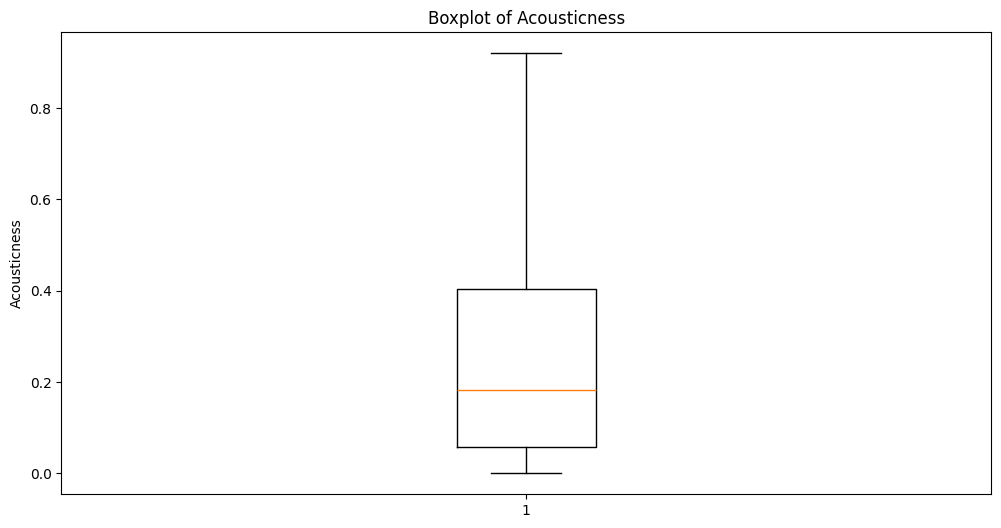

In [12]:
plt.figure(figsize=(12, 6))
plt.boxplot(df['acousticness'])
plt.title('Boxplot of Acousticness')
plt.ylabel('Acousticness')
plt.show()

In [11]:
# Treating the outliers
iqr = df['acousticness'].quantile(0.75) - df['acousticness'].quantile(0.25)
upperbound = df['acousticness'].quantile(0.75) + (1.5 * iqr)
lowerbound = df["acousticness"].quantile(0.25) - (1.5 * iqr)

df["acousticness"] = df["acousticness"].clip(lower=lowerbound, upper=upperbound)

### Danceability

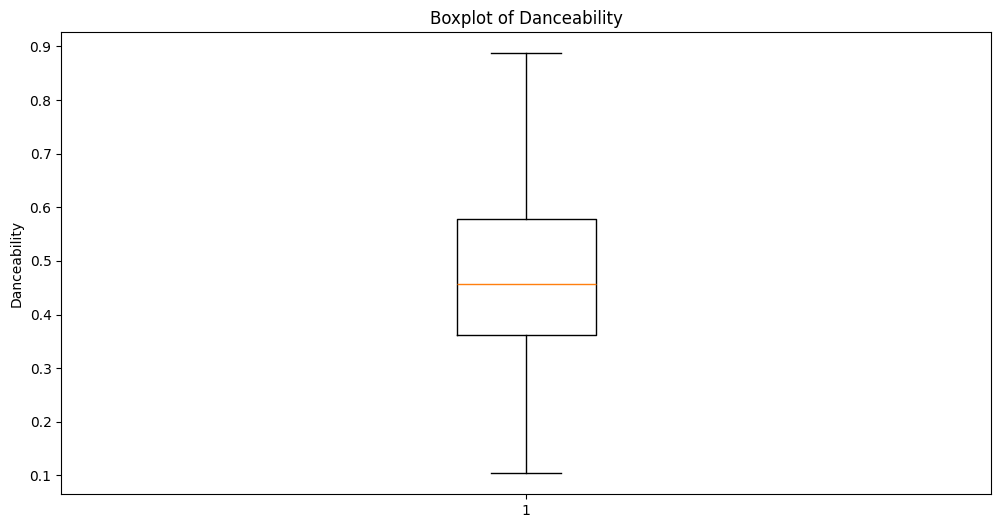

In [13]:
plt.figure(figsize=(12, 6))
plt.boxplot(df['danceability'])
plt.title('Boxplot of Danceability')
plt.ylabel('Danceability')
plt.show()

### Energy

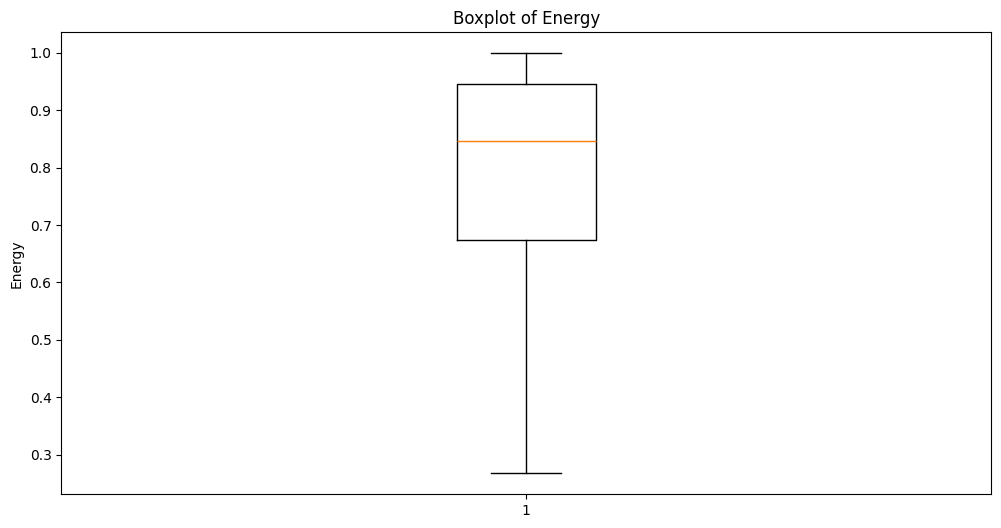

In [16]:
plt.figure(figsize=(12, 6))
plt.boxplot(df['energy'])
plt.title('Boxplot of Energy')
plt.ylabel('Energy')
plt.show()

In [15]:
iqrenergy = df['energy'].quantile(0.75) - df['energy'].quantile(0.25)
upperboundenergy = df['energy'].quantile(0.75) + (1.5 * iqrenergy)
lowerboundenergy = df['energy'].quantile(0.25) - (1.5 * iqrenergy)

df['energy'] = df['energy'].clip(lower=lowerboundenergy, upper=upperboundenergy)

### Instrumentalness

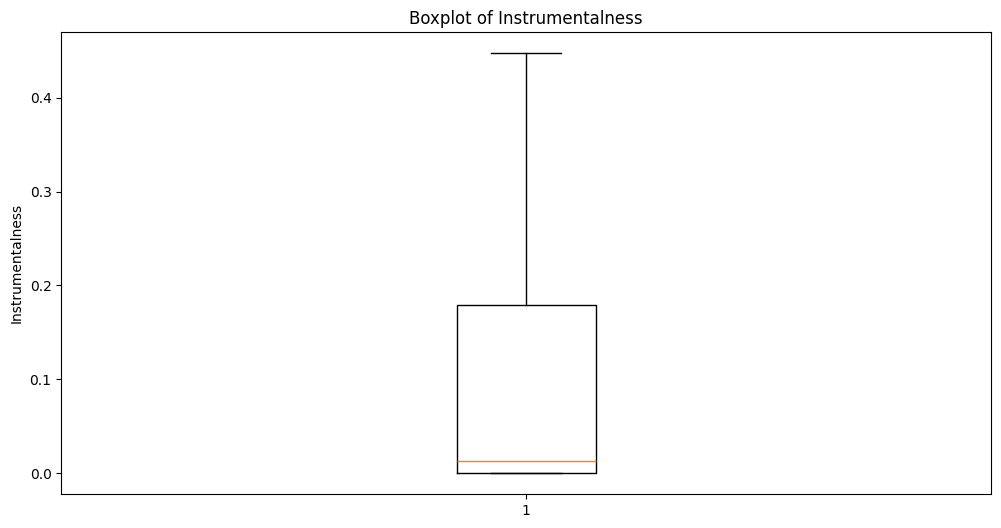

In [18]:
plt.figure(figsize=(12, 6))
plt.boxplot(df['instrumentalness'])
plt.title('Boxplot of Instrumentalness')
plt.ylabel('Instrumentalness')
plt.show()

In [17]:
iqrinstrument = df['instrumentalness'].quantile(0.75) - df['instrumentalness'].quantile(0.25)
upperboundinstrument = df['instrumentalness'].quantile(0.75) + (1.5 * iqrinstrument)
lowerboundinstrument = df['instrumentalness'].quantile(0.25) - (1.5 * iqrinstrument)

df['instrumentalness'] = df['instrumentalness'].clip(lower=lowerboundinstrument, upper=upperboundinstrument)

### Liveness

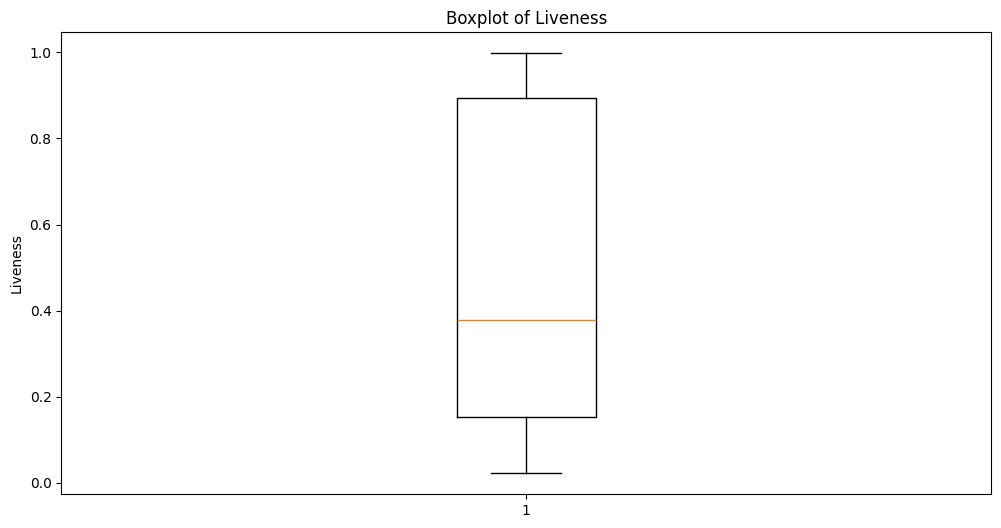

In [19]:
plt.figure(figsize=(12, 6))
plt.boxplot(df['liveness'])
plt.title('Boxplot of Liveness')
plt.ylabel('Liveness')
plt.show()

### Loudness

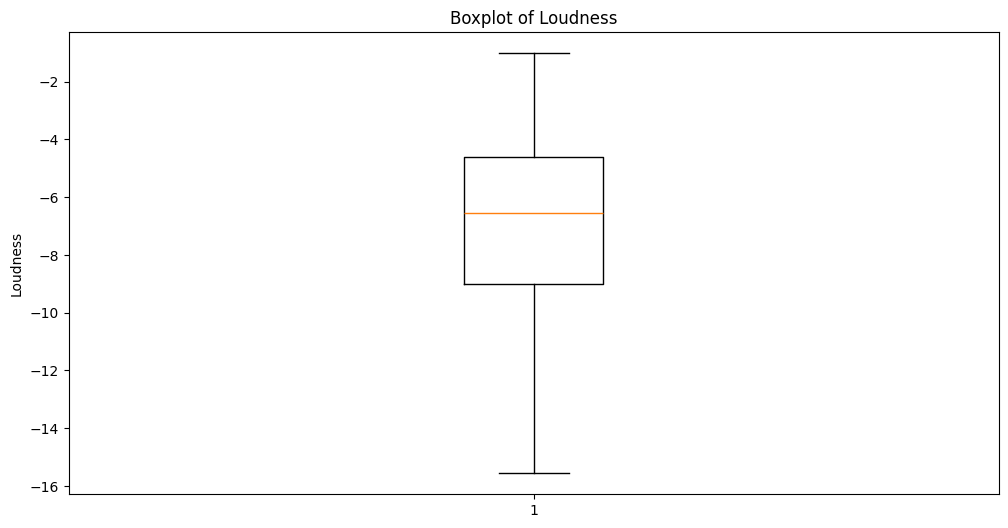

In [22]:
plt.figure(figsize=(12, 6))
plt.boxplot(df['loudness'])
plt.title('Boxplot of Loudness')
plt.ylabel('Loudness')
plt.show()

In [21]:
iqrloudness = df['loudness'].quantile(0.75) - df['loudness'].quantile(0.25)
upperboundloudness = df['loudness'].quantile(0.75) + (1.5 * iqrloudness)
lowerboundloudness = df['loudness'].quantile(0.25) - (1.5 * iqrloudness)

df['loudness'] = df['loudness'].clip(lower=lowerboundloudness, upper=upperboundloudness)

### Speechiness

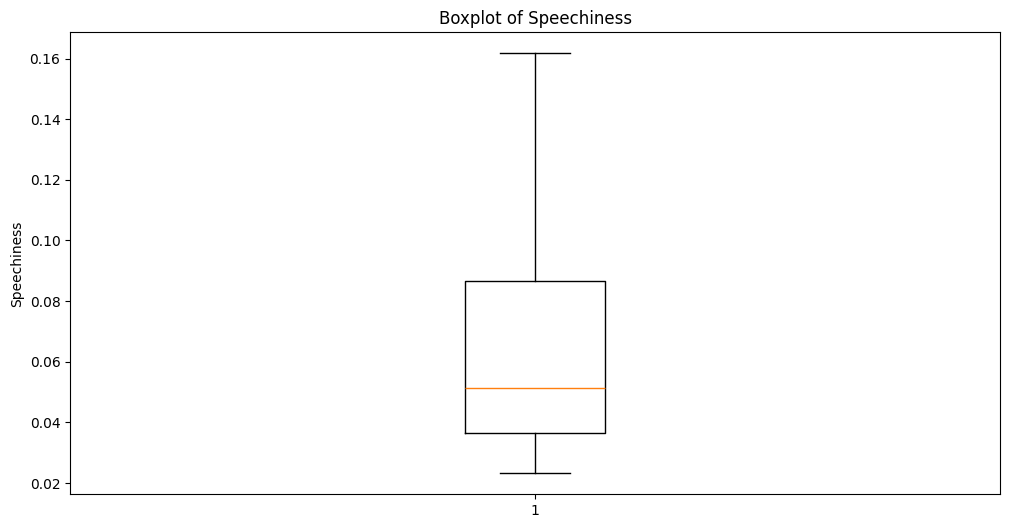

In [25]:
plt.figure(figsize=(12, 6))
plt.boxplot(df['speechiness'])
plt.title('Boxplot of Speechiness')
plt.ylabel('Speechiness')
plt.show()

In [24]:
iqrspeechiness = df['speechiness'].quantile(0.75) - df['speechiness'].quantile(0.25)
upperboundspeechiness = df['speechiness'].quantile(0.75) + (1.5 * iqrspeechiness)
lowerboundspeechiness = df['speechiness'].quantile(0.25) - (1.5 * iqrspeechiness)

df['speechiness'] = df['speechiness'].clip(lower=lowerboundspeechiness, upper=upperboundspeechiness)

### Tempo

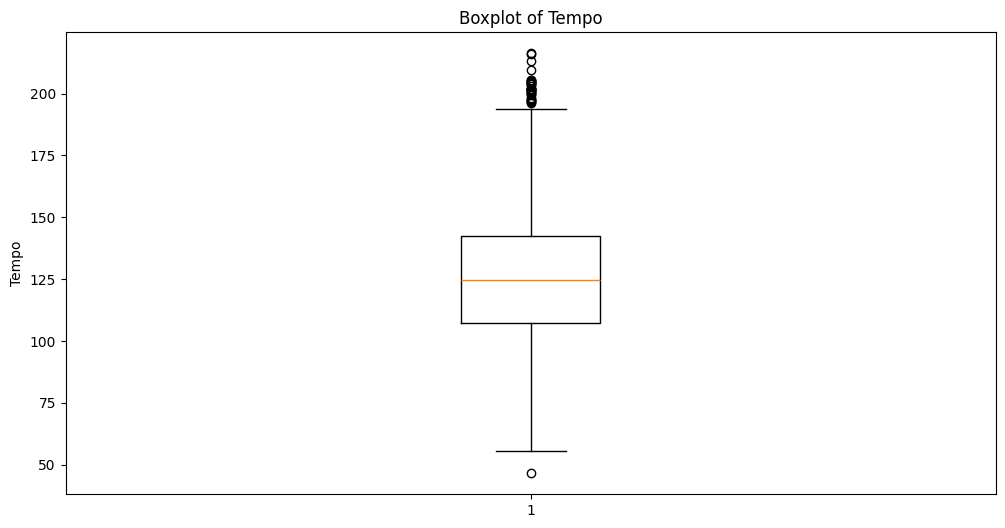

In [26]:
plt.figure(figsize=(12, 6))
plt.boxplot(df['tempo'])
plt.title('Boxplot of Tempo')
plt.ylabel('Tempo')
plt.show()

In [27]:
iqrtempo = df['tempo'].quantile(0.75) - df['tempo'].quantile(0.25)
upperboundtempo = df['tempo'].quantile(0.75) + (1.5 * iqrtempo)
lowerboundtempo = df['tempo'].quantile(0.25) - (1.5 * iqrtempo)

df['tempo'] = df['tempo'].clip(lower=lowerboundtempo, upper=upperboundtempo)

### Valence

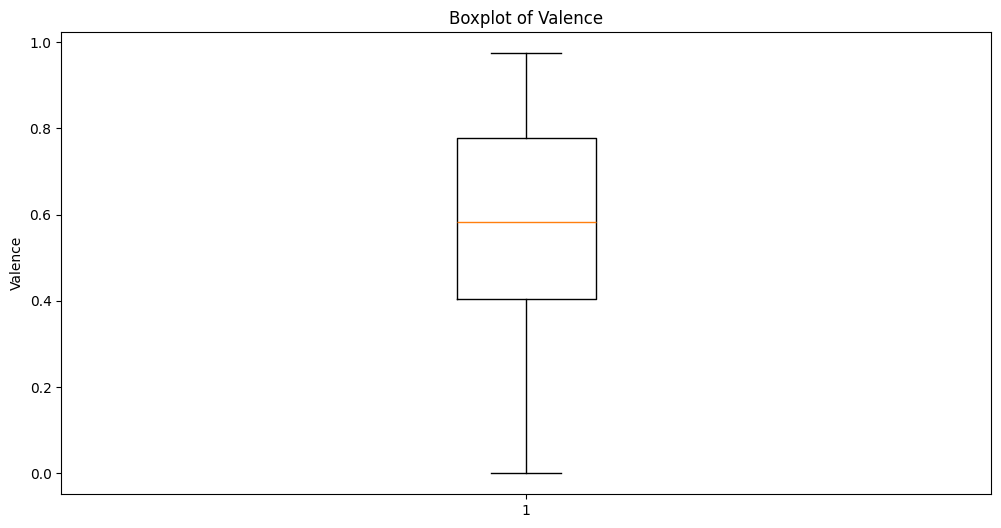

In [28]:
plt.figure(figsize=(12, 6))
plt.boxplot(df['valence'])
plt.title('Boxplot of Valence')
plt.ylabel('Valence')
plt.show()

### Popularity

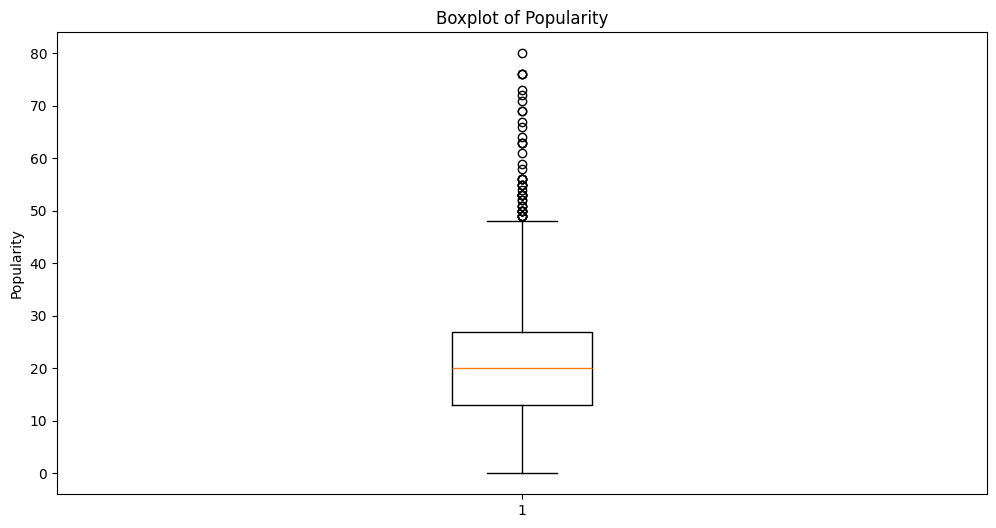

In [ ]:
plt.figure(figsize=(12, 6))
plt.boxplot(df['popularity'])
plt.title('Boxplot of Popularity')
plt.ylabel('Popularity')
plt.show()